In [1]:
# Imports and settings (Task 3-2 CNN)

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.datasets import fashion_mnist

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.20.0


In [2]:
# Load and preprocess Fashion-MNIST for CNN (reshape + normalize)

(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# reshape to (28,28,1) and normalize to [0,1] (Lecture 3 style)
x_train = x_train.reshape(-1, 28, 28, 1).astype("float32") / 255.0
x_test  = x_test.reshape(-1, 28, 28, 1).astype("float32") / 255.0

print("x_train:", x_train.shape, "y_train:", y_train.shape)
print("x_test :", x_test.shape,  "y_test :", y_test.shape)
print("min/max:", x_train.min(), x_train.max())

x_train: (60000, 28, 28, 1) y_train: (60000,)
x_test : (10000, 28, 28, 1) y_test : (10000,)
min/max: 0.0 1.0


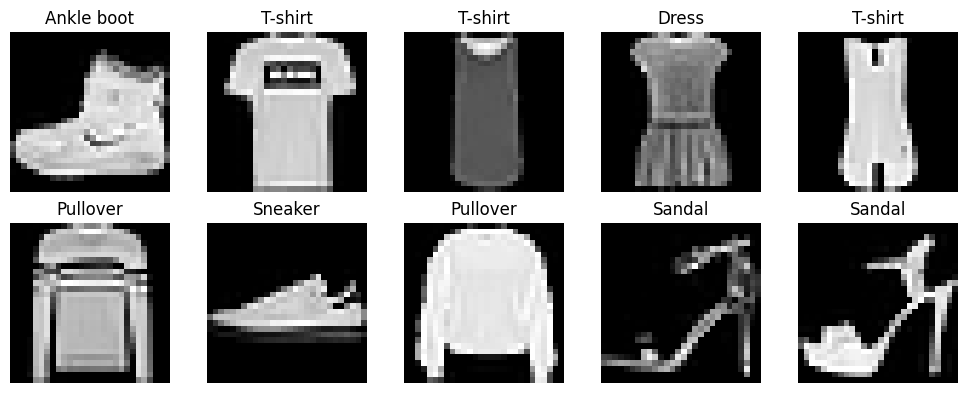

In [3]:
# Show sample images (sanity check)

class_names = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

plt.figure(figsize=(10, 4))
for i in range(10):
    ax = plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

In [4]:
# Build Baseline CNN (Conv→ReLU→Pool→Conv→ReLU→Pool→Dense→Softmax)

def build_baseline_cnn():
    model = Sequential([
        layers.Conv2D(32, (3,3), activation="relu", input_shape=(28,28,1)),
        layers.MaxPooling2D((2,2)),

        layers.Conv2D(64, (3,3), activation="relu"),
        layers.MaxPooling2D((2,2)),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(10, activation="softmax")
    ])
    model.compile(
        optimizer=Adam(),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

cnn_baseline = build_baseline_cnn()
cnn_baseline.summary()

c:\Users\hasan\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# Train Baseline CNN (epochs=5) + evaluate

history_base = cnn_baseline.fit(
    x_train, y_train,
    epochs=5,
    batch_size=128,
    validation_data=(x_test, y_test),
    verbose=1
)

test_loss_base, test_acc_base = cnn_baseline.evaluate(x_test, y_test, verbose=0)
print("Baseline Test Loss:", test_loss_base)
print("Baseline Test Accuracy:", test_acc_base)

Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 18s 35ms/step - accuracy: 0.8069 - loss: 0.5374 - val_accuracy: 0.8583 - val_loss: 0.3945
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 15s 33ms/step - accuracy: 0.8743 - loss: 0.3505 - val_accuracy: 0.8705 - val_loss: 0.3548
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 16s 34ms/step - accuracy: 0.8901 - loss: 0.3029 - val_accuracy: 0.8818 - val_loss: 0.3296
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 16s 34ms/step - accuracy: 0.9013 - loss: 0.2712 - val_accuracy: 0.8874 - val_loss: 0.3103
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 16s 34ms/step - accuracy: 0.9099 - loss: 0.2461 - val_accuracy: 0.8945 - val_loss: 0.2876
Baseline Test Loss: 0.2875739336013794
Baseline Test Accuracy: 0.8945000171661377


In [6]:
# Build CNN with Dropout (regularization)

def build_cnn_with_dropout():
    model = Sequential([
        layers.Conv2D(32, (3,3), activation="relu", input_shape=(28,28,1)),
        layers.MaxPooling2D((2,2)),

        layers.Conv2D(64, (3,3), activation="relu"),
        layers.MaxPooling2D((2,2)),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),  # Lecture-style dropout
        layers.Dense(10, activation="softmax")
    ])
    model.compile(
        optimizer=Adam(),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

cnn_dropout = build_cnn_with_dropout()
cnn_dropout.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Train CNN + Dropout (epochs=5) + evaluate

history_dropout = cnn_dropout.fit(
    x_train, y_train,
    epochs=5,
    batch_size=128,
    validation_data=(x_test, y_test),
    verbose=1
)

test_loss_dropout, test_acc_dropout = cnn_dropout.evaluate(x_test, y_test, verbose=0)
print("Dropout CNN Test Loss:", test_loss_dropout)
print("Dropout CNN Test Accuracy:", test_acc_dropout)

Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 18s 35ms/step - accuracy: 0.7669 - loss: 0.6520 - val_accuracy: 0.8485 - val_loss: 0.4261
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 15s 33ms/step - accuracy: 0.8442 - loss: 0.4348 - val_accuracy: 0.8659 - val_loss: 0.3658
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 16s 34ms/step - accuracy: 0.8649 - loss: 0.3794 - val_accuracy: 0.8759 - val_loss: 0.3406
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 16s 35ms/step - accuracy: 0.8751 - loss: 0.3470 - val_accuracy: 0.8790 - val_loss: 0.3311
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 16s 33ms/step - accuracy: 0.8847 - loss: 0.3210 - val_accuracy: 0.8916 - val_loss: 0.3000
Dropout CNN Test Loss: 0.30004268884658813
Dropout CNN Test Accuracy: 0.8916000127792358


In [8]:
# Build CNN with Batch Normalization

def build_cnn_with_bn():
    model = Sequential([
        layers.Conv2D(32, (3,3), input_shape=(28,28,1)),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2,2)),

        layers.Conv2D(64, (3,3)),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2,2)),

        layers.Flatten(),
        layers.Dense(128),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dense(10, activation="softmax")
    ])
    model.compile(
        optimizer=Adam(),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

cnn_bn = build_cnn_with_bn()
cnn_bn.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 26, 26, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 26, 26, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 11, 11, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 11, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,930 (882.54 KB)

 Trainable params: 225,482 (880.79 KB)

 Non-trainable params: 448 (1.75 KB)

In [9]:
# Train CNN + Batch Normalization (epochs=5) + evaluate

history_bn = cnn_bn.fit(
    x_train, y_train,
    epochs=5,
    batch_size=128,
    validation_data=(x_test, y_test),
    verbose=1
)

test_loss_bn, test_acc_bn = cnn_bn.evaluate(x_test, y_test, verbose=0)
print("BN CNN Test Loss:", test_loss_bn)
print("BN CNN Test Accuracy:", test_acc_bn)

Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 37s 72ms/step - accuracy: 0.8630 - loss: 0.3825 - val_accuracy: 0.7747 - val_loss: 0.6341
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 31s 67ms/step - accuracy: 0.9080 - loss: 0.2533 - val_accuracy: 0.8809 - val_loss: 0.3214
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 39s 84ms/step - accuracy: 0.9266 - loss: 0.2046 - val_accuracy: 0.8487 - val_loss: 0.4453
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 36s 76ms/step - accuracy: 0.9399 - loss: 0.1696 - val_accuracy: 0.8531 - val_loss: 0.4205
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 34s 73ms/step - accuracy: 0.9508 - loss: 0.1405 - val_accuracy: 0.8900 - val_loss: 0.3224
BN CNN Test Loss: 0.32235243916511536
BN CNN Test Accuracy: 0.8899999856948853


In [10]:
# Build CNN for Data Augmentation experiment

def build_cnn_aug():
    model = Sequential([
        layers.Conv2D(32, (3,3), activation="relu", input_shape=(28,28,1)),
        layers.MaxPooling2D((2,2)),

        layers.Conv2D(64, (3,3), activation="relu"),
        layers.MaxPooling2D((2,2)),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(10, activation="softmax")
    ])
    model.compile(
        optimizer=Adam(),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

cnn_aug = build_cnn_aug()
cnn_aug.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Train CNN with ImageDataGenerator (data augmentation)

datagen = ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1
)

datagen.fit(x_train)

history_aug = cnn_aug.fit(
    datagen.flow(x_train, y_train, batch_size=128),
    epochs=5,
    validation_data=(x_test, y_test),
    verbose=1
)

test_loss_aug, test_acc_aug = cnn_aug.evaluate(x_test, y_test, verbose=0)
print("Augmented CNN Test Loss:", test_loss_aug)
print("Augmented CNN Test Accuracy:", test_acc_aug)

Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 47s 97ms/step - accuracy: 0.7279 - loss: 0.7341 - val_accuracy: 0.7939 - val_loss: 0.5250
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 35s 75ms/step - accuracy: 0.8033 - loss: 0.5238 - val_accuracy: 0.8434 - val_loss: 0.4313
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 39s 83ms/step - accuracy: 0.8240 - loss: 0.4658 - val_accuracy: 0.8523 - val_loss: 0.3979
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 34s 72ms/step - accuracy: 0.8391 - loss: 0.4259 - val_accuracy: 0.8656 - val_loss: 0.3691
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 35s 74ms/step - accuracy: 0.8484 - loss: 0.4030 - val_accuracy: 0.8729 - val_loss: 0.3562
Augmented CNN Test Loss: 0.3561873435974121
Augmented CNN Test Accuracy: 0.8729000091552734


In [12]:
# Results comparison table (Baseline vs Dropout vs BN vs Augmentation)

results = [
    ("Baseline",  test_loss_base,    test_acc_base),
    ("Dropout",   test_loss_dropout, test_acc_dropout),
    ("BatchNorm", test_loss_bn,      test_acc_bn),
    ("Augmented", test_loss_aug,     test_acc_aug),
]

print(f"{'Model':<12} {'Test Loss':<12} {'Test Accuracy':<12}")
print("-" * 40)
for name, loss, acc in results:
    print(f"{name:<12} {loss:<12.4f} {acc:<12.4f}")

Model        Test Loss    Test Accuracy
----------------------------------------
Baseline     0.2876       0.8945      
Dropout      0.3000       0.8916      
BatchNorm    0.3224       0.8900      
Augmented    0.3562       0.8729      
